# Iris Flower Classification

---

### Team Member Details
* **Team Leader Name:** *Harshil Kumar Verma Roll No: 26150309*  
* **Team Members:** *Arnab Patra Roll No: 26150327, Atharva Tukaram Patil Roll No: 26150307, Himanshu Kumar Roll No: 26150147*
* **Course / Branch:** B.Tech Computer Science & Engineering (CSE)
* **Institution:** Dr. D. Y. Patil School of Science & Technology
* **Submitted To:** *Dr. Sarika Kalyanakar*

---

### Project Description
This mini-project implements an end-to-end supervised machine learning pipeline to classify Iris flowers into three species (*Iris-setosa*, *Iris-versicolor*, and *Iris-virginica*) based on four morphological measurements: sepal length, sepal width, petal length, and petal width. The workflow begins with Exploratory Data Analysis (EDA) to inspect feature distributions and correlations, followed by feature standardization (`StandardScaler`) and **Principal Component Analysis (PCA)** to reduce the 4-dimensional feature space into 2 principal components while retaining ~96% of total variance. Finally, two classifiers—**K-Nearest Neighbors (KNN)** and **Support Vector Machine (SVM)**—are trained on the leakage-free PCA-transformed training data and evaluated using test accuracy, confusion matrices, classification reports, and 2D decision boundary visualizations.

**Pipeline:** EDA → StandardScaler → PCA (2 components) → KNN & SVM → Evaluation & Comparison

## 1. Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42  # for reproducibility

Matplotlib is building the font cache; this may take a moment.


## 2. Load the Dataset

In [ ]:
iris = load_iris()

# Build a DataFrame for convenient EDA
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["target"] = iris.target
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

print("Shape:", df.shape)
df.head()

Shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 3. Exploratory Data Analysis (EDA)

In [ ]:
# --- Structure, types, and missing values ---
df.info()
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 8.4 KB

Missing values per column:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Duplicate rows: 1


In [ ]:
# --- Summary statistics ---
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5
target,150.0,1.000000,0.819232,0.0,0.0,1.00,2.0,2.0


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


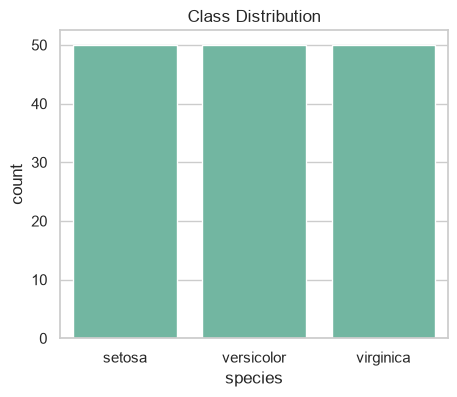

In [ ]:
# --- Class balance ---
print(df["species"].value_counts())

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="species")
plt.title("Class Distribution")
plt.show()

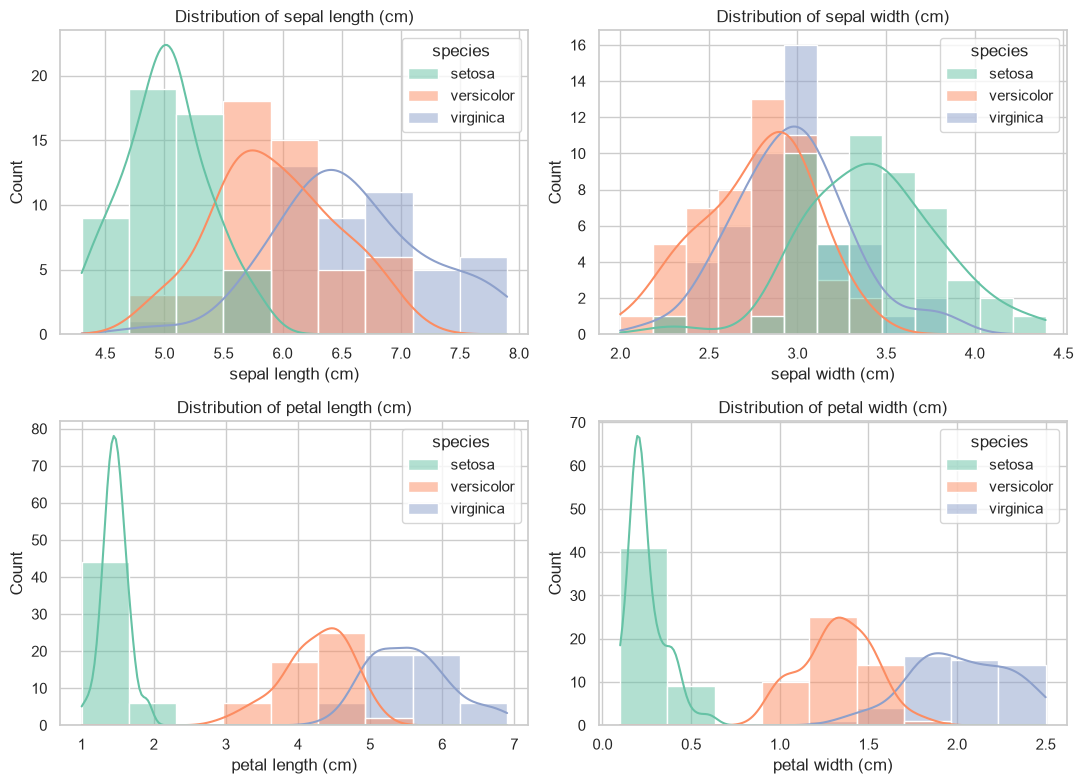

In [ ]:
# --- Feature distributions by species ---
features = iris.feature_names
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.ravel(), features):
    sns.histplot(data=df, x=feat, hue="species", kde=True, ax=ax)
    ax.set_title(f"Distribution of {feat}")
plt.tight_layout()
plt.show()

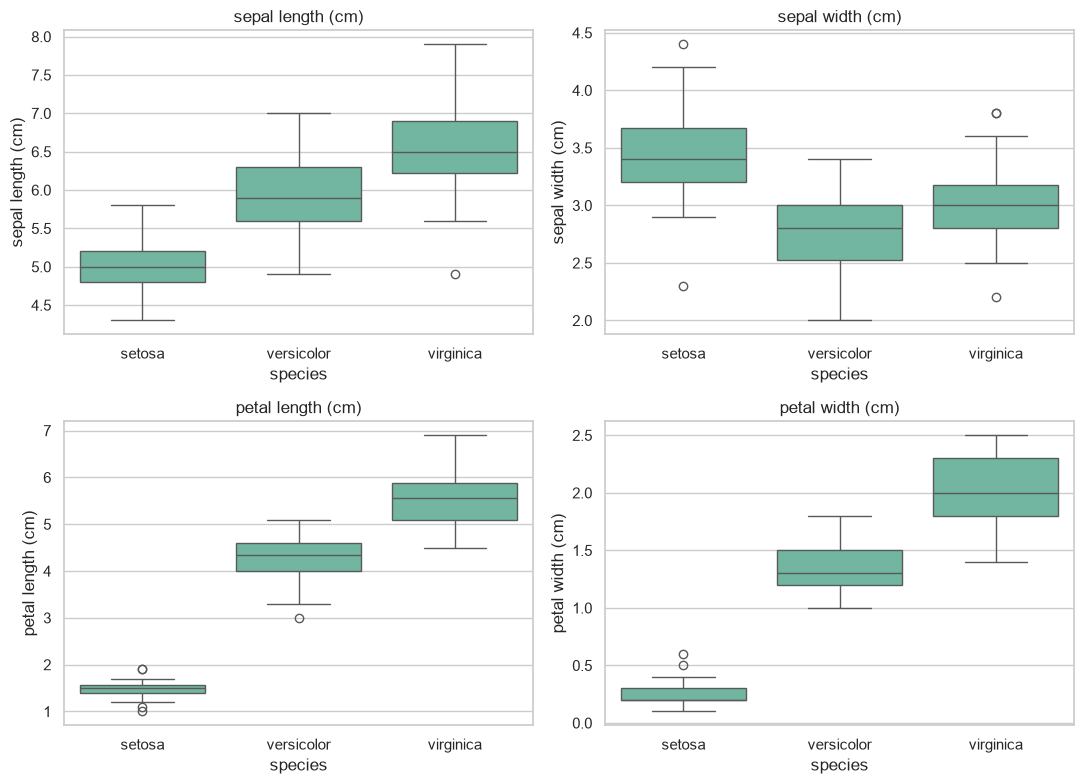

In [ ]:
# --- Boxplots: spread and outliers per species ---
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="species", y=feat, ax=ax)
    ax.set_title(feat)
plt.tight_layout()
plt.show()

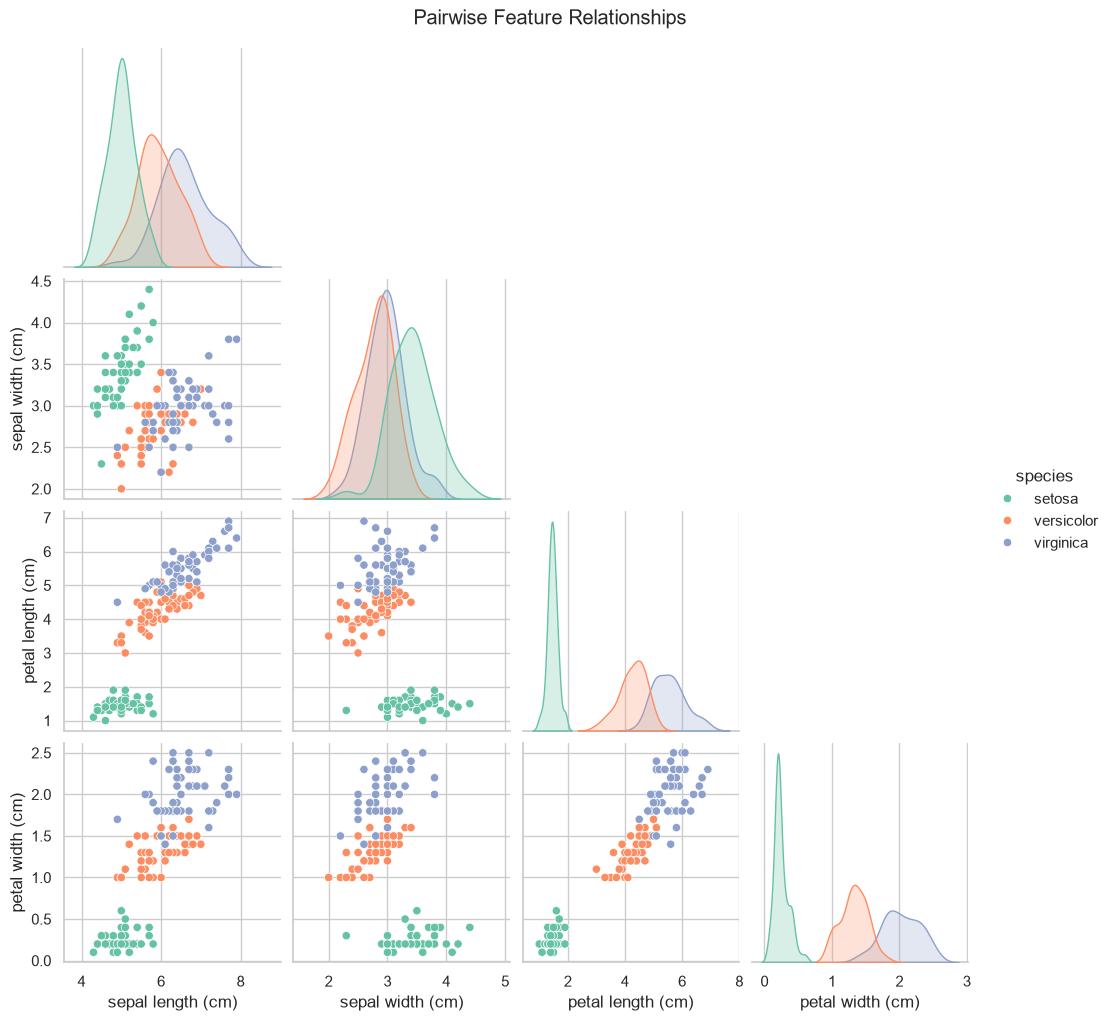

In [ ]:
# --- Pairplot: pairwise relationships ---
sns.pairplot(df.drop(columns="target"), hue="species", corner=True)
plt.suptitle("Pairwise Feature Relationships", y=1.02)
plt.show()

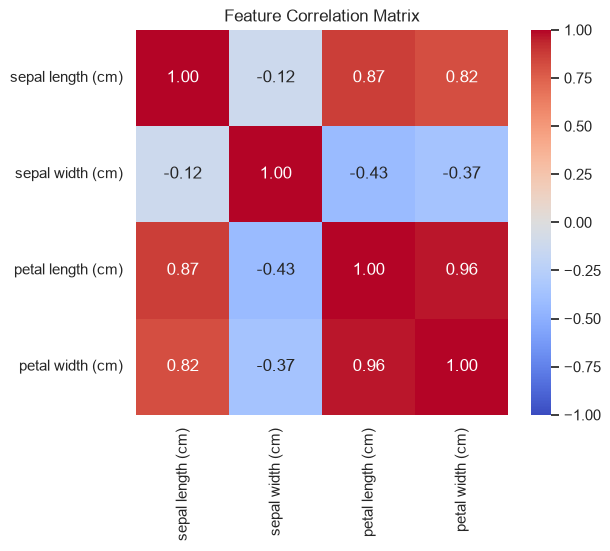

In [ ]:
# --- Correlation heatmap ---
plt.figure(figsize=(6, 5))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Feature Correlation Matrix")
plt.show()

## 4. Standardization + PCA (for visualization)
PCA is sensitive to feature scale, so we standardize first (mean 0, std 1).
Here we fit on the full dataset **only to visualize** the structure of the data.

In [ ]:
X = df[features].values
y = df["target"].values

X_scaled = StandardScaler().fit_transform(X)

pca_vis = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_vis = pca_vis.fit_transform(X_scaled)

print("Explained variance ratio:", pca_vis.explained_variance_ratio_.round(4))
print(f"Total variance retained : {pca_vis.explained_variance_ratio_.sum():.2%}")

# Which original features drive each component?
pd.DataFrame(pca_vis.components_, columns=features, index=["PC1", "PC2"]).round(3)

Explained variance ratio: [0.7296 0.2285]
Total variance retained : 95.81%


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
PC1,0.521,-0.269,0.580,0.565
PC2,0.377,0.923,0.024,0.067


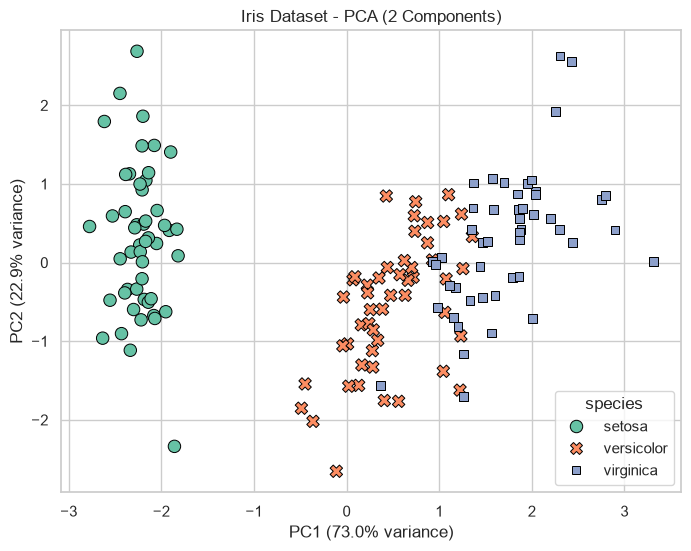

In [ ]:
# --- 2D scatter plot of PCA results ---
pca_df = pd.DataFrame(X_pca_vis, columns=["PC1", "PC2"])
pca_df["species"] = df["species"]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="species", style="species", s=80, edgecolor="k")
plt.xlabel(f"PC1 ({pca_vis.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca_vis.explained_variance_ratio_[1]:.1%} variance)")
plt.title("Iris Dataset - PCA (2 Components)")
plt.show()

## 5. Train/Test Split and Leakage-Free Preprocessing
To avoid **data leakage**, we split first, then fit the scaler and PCA on the **training set only**
and apply them to the test set.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y  # stratify keeps class ratios equal
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on train only
X_test_s = scaler.transform(X_test)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_s)  # fit on train only
X_test_pca = pca.transform(X_test_s)

print("Train shape:", X_train_pca.shape, "| Test shape:", X_test_pca.shape)

Train shape: (105, 2) | Test shape: (45, 2)


## 6. Train the Models (KNN and SVM)

In [ ]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train_pca, y_train)
print("Models trained:", list(models))

Models trained: ['KNN', 'SVM']


## 7. Evaluation

KNN  |  Accuracy: 0.9111
Confusion Matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



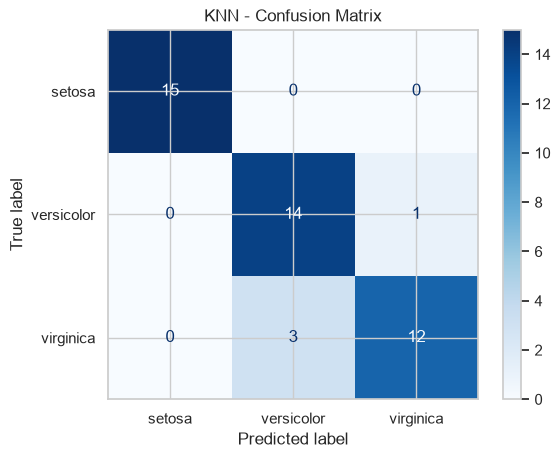

SVM  |  Accuracy: 0.9111
Confusion Matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



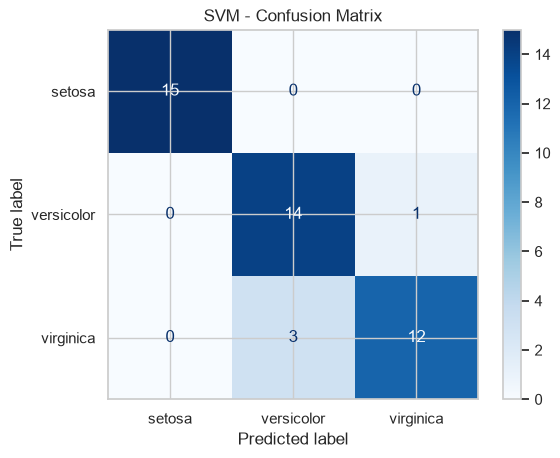

In [ ]:
results = {}
class_names = iris.target_names

for name, model in models.items():
    y_pred = model.predict(X_test_pca)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc

    print("=" * 60)
    print(f"{name}  |  Accuracy: {acc:.4f}")
    print("=" * 60)
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("\nClassification Report:\n",
          classification_report(y_test, y_pred, target_names=class_names))

    # Confusion matrix heatmap
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, cmap="Blues")
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

## 8. Visual Comparison of Accuracies

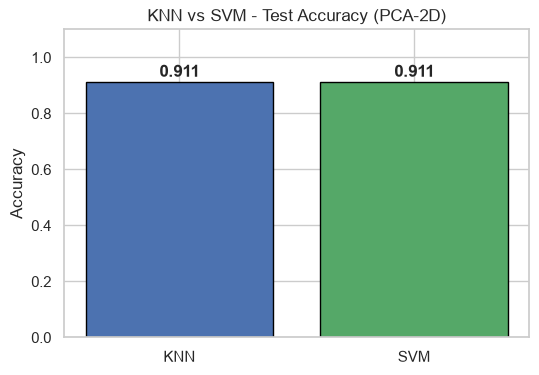

In [ ]:
plt.figure(figsize=(6, 4))
bars = plt.bar(results.keys(), results.values(), color=["#4C72B0", "#55A868"], edgecolor="k")
plt.ylim(0, 1.1)
plt.ylabel("Accuracy")
plt.title("KNN vs SVM - Test Accuracy (PCA-2D)")
for bar, acc in zip(bars, results.values()):
    plt.text(bar.get_x() + bar.get_width() / 2, acc + 0.02, f"{acc:.3f}", ha="center", fontweight="bold")
plt.show()

## 9. Bonus: Decision Boundaries in PCA Space

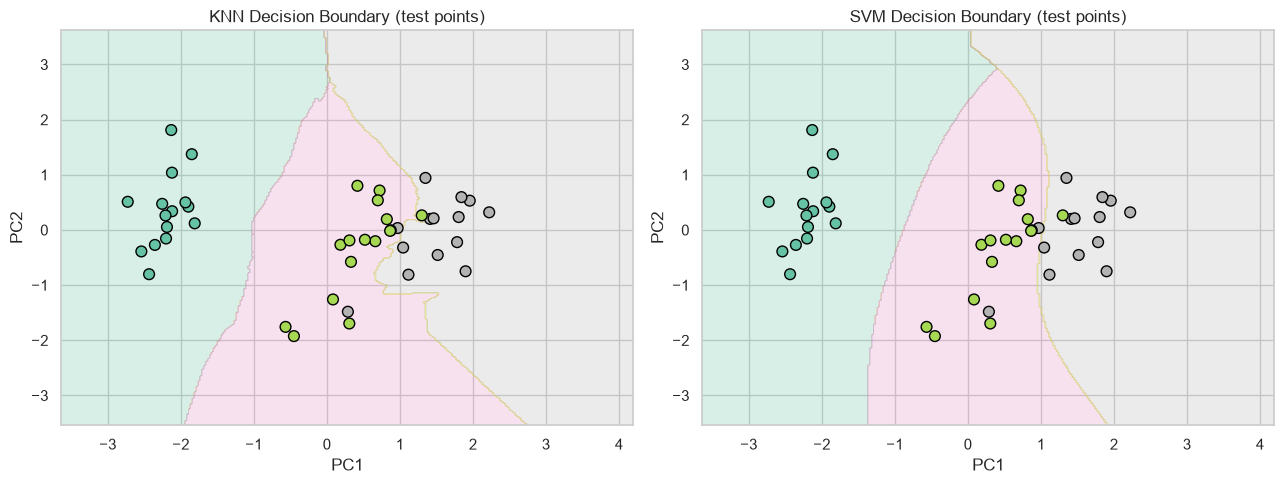

In [ ]:
# Visualize how each classifier partitions the 2D PCA plane
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, model) in zip(axes, models.items()):
    Z = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="Set2")
    ax.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap="Set2", edgecolor="k", s=60)
    ax.set_title(f"{name} Decision Boundary (test points)")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

## 10. Conclusion
- PCA with 2 components retains most (~96%) of the variance in the standardized data.
- *Setosa* is perfectly separable; *versicolor* and *virginica* overlap slightly, which is where errors occur.
- Compare the accuracy bar chart and reports above to see which model generalizes better on this split.